## Importação e Início

In [1]:
# utilizar os Dataframes do Pandas para manipular as instâncias
import pandas as pd
import numpy as np
# matplotlib e seaborn para visualizar
import matplotlib.pyplot as plt
import seaborn as sns
# gdown para baixar os dados
import gdown
plt.style.use('ggplot')

In [2]:
url = 'https://drive.google.com/file/d/10izoanxrZJnQzkV9UpPI-DX9bt2mYG62/view'
output = 'filmes.json'
gdown.download(url=url, output=output, quiet=False)

Downloading...
From: https://drive.google.com/uc?id=10izoanxrZJnQzkV9UpPI-DX9bt2mYG62
To: c:\Users\PC\Desktop\Filmesdata\filmes.json
100%|██████████| 31.8M/31.8M [00:03<00:00, 9.74MB/s]


'filmes.json'

In [3]:
df = pd.read_json('filmes.json', orient='records')

## Primeira Análise

In [4]:
df.head()

,adult,backdrop_path,belongs_to_collection,budget,genres,homepage,id,imdb_id,origin_country,original_language,...,softcore,spoken_languages,status,tagline,title,video,vote_average,vote_count,profit,roi
0,False,/7RyHsO4yDXtBv1zUU3mTpHeQ0d5.jpg,"{'id': 86311, 'name': 'The Avengers Collection...",356000000,"[{'id': 12, 'name': 'Adventure'}, {'id': 878, ...",https://www.marvel.com/movies/avengers-endgame,299534,tt4154796,[US],en,...,False,"[{'english_name': 'English', 'iso_639_1': 'en'...",Released,Avenge the fallen.,Avengers: Endgame,False,8.247,29099,2582567784,7.2544
1,False,/vL5LR6WdxWPjLPFRLe133jXWsh5.jpg,"{'id': 87096, 'name': 'Avatar Collection', 'po...",237000000,"[{'id': 878, 'name': 'Science Fiction'}, {'id'...",https://www.avatar.com/movies/avatar,19995,tt0499549,[US],en,...,False,"[{'english_name': 'English', 'iso_639_1': 'en'...",Released,Enter the world of Pandora.,Avatar,False,7.611,34904,2686706026,11.3363
2,False,/r08LxMJCbf1SiJIWeyH9aJmdqwC.jpg,"{'id': 531241, 'name': 'Spider-Man (MCU) Colle...",225000000,"[{'id': 878, 'name': 'Science Fiction'}, {'id'...",https://spidermanbrandnewday.movie,969681,tt22084616,[US],en,...,False,"[{'english_name': 'English', 'iso_639_1': 'en'...",Released,A brand new day starts now.,Spider-Man: Brand New Day,False,8.468,6037,2291291000,10.1835
3,False,/kJsPVzdyBrYHLomuNv5SJDXUQ2f.jpg,"{'id': 87096, 'name': 'Avatar Collection', 'po...",460000000,"[{'id': 28, 'name': 'Action'}, {'id': 12, 'nam...",https://www.avatar.com/movies/avatar-the-way-o...,76600,tt1630029,[US],en,...,False,"[{'english_name': 'English', 'iso_639_1': 'en'...",Released,Return to Pandora.,Avatar: The Way of Water,False,7.581,14813,1874484620,4.0750
4,False,/gd9kxeEEONj5SECs4GA8Ddn3czI.jpg,"{'id': 1449595, 'name': 'Ne Zha Collection', '...",80000000,"[{'id': 16, 'name': 'Animation'}, {'id': 28, '...",https://a24films.com/films/ne-zha-2,980477,tt34956443,[CN],zh,...,False,"[{'english_name': 'Mandarin', 'iso_639_1': 'zh...",Released,Witness a hero reborn.,Ne Zha 2,False,8.204,856,2190700370,27.3838


In [5]:
df.info()
df.columns

<class 'pandas.DataFrame'>
RangeIndex: 16541 entries, 0 to 16540
Data columns (total 29 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   adult                  16541 non-null  bool   
 1   backdrop_path          14475 non-null  str    
 2   belongs_to_collection  2812 non-null   object 
 3   budget                 16541 non-null  int64  
 4   genres                 16541 non-null  object 
 5   homepage               16541 non-null  str    
 6   id                     16541 non-null  int64  
 7   imdb_id                14108 non-null  str    
 8   origin_country         16541 non-null  object 
 9   original_language      16541 non-null  str    
 10  original_title         16541 non-null  str    
 11  overview               16541 non-null  str    
 12  popularity             16541 non-null  float64
 13  poster_path            16190 non-null  str    
 14  production_companies   16541 non-null  object 
 15  production_co

Index(['adult', 'backdrop_path', 'belongs_to_collection', 'budget', 'genres',
       'homepage', 'id', 'imdb_id', 'origin_country', 'original_language',
       'original_title', 'overview', 'popularity', 'poster_path',
       'production_companies', 'production_countries', 'release_date',
       'revenue', 'runtime', 'softcore', 'spoken_languages', 'status',
       'tagline', 'title', 'video', 'vote_average', 'vote_count', 'profit',
       'roi'],
      dtype='str')

### Retirada de Colunas Inúteis

In [6]:
df.drop(columns=['backdrop_path','homepage', 'poster_path','popularity','status','adult','tagline'], inplace=True)

### Retirada de Outliers

In [7]:
quantidade = (df['budget'] < 10).sum()
print(quantidade)

599


In [8]:
df = df[
    (df['roi'] <= 50000) &
    (df['budget'] > 1000) &
    (df['vote_count'] > 50)
].copy()

## Divisão por Filme

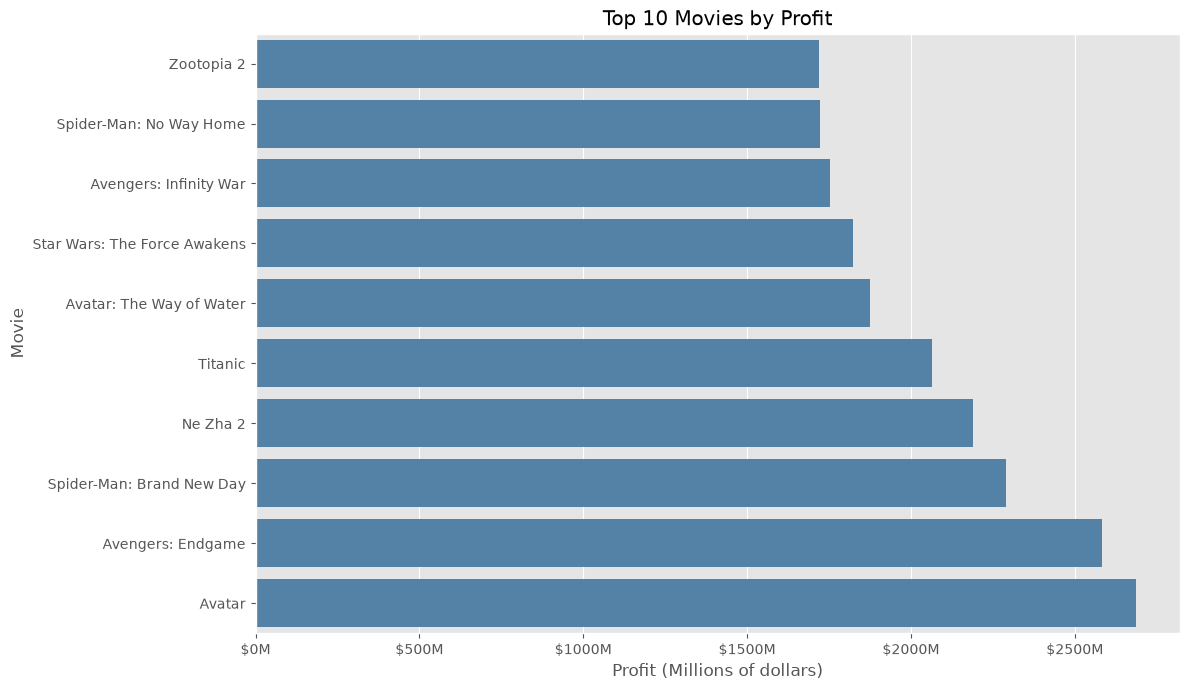

In [9]:
top_10_movies_profit = df.nlargest(10, 'profit').sort_values('profit')

plt.figure(figsize=(12, 7))
ax = sns.barplot(
    data=top_10_movies_profit,
    x='profit',
    y='title',
    color='steelblue'
)

ax.set_title('Top 10 Movies by Profit')
ax.set_xlabel('Profit (Millions of dollars)')
ax.set_ylabel('Movie')

ax.xaxis.set_major_formatter(
    plt.FuncFormatter(lambda value, _: f'${value / 1_000_000:.0f}M')
)

plt.tight_layout()
plt.show()

## Divisão Por Gênero

In [10]:
df_genres = df.explode('genres').copy()
df_genres['genre'] = df_genres['genres'].apply(
    lambda x: x.get('name') if isinstance(x, dict) else np.nan
)
df_genres.drop(columns='genres', inplace=True)

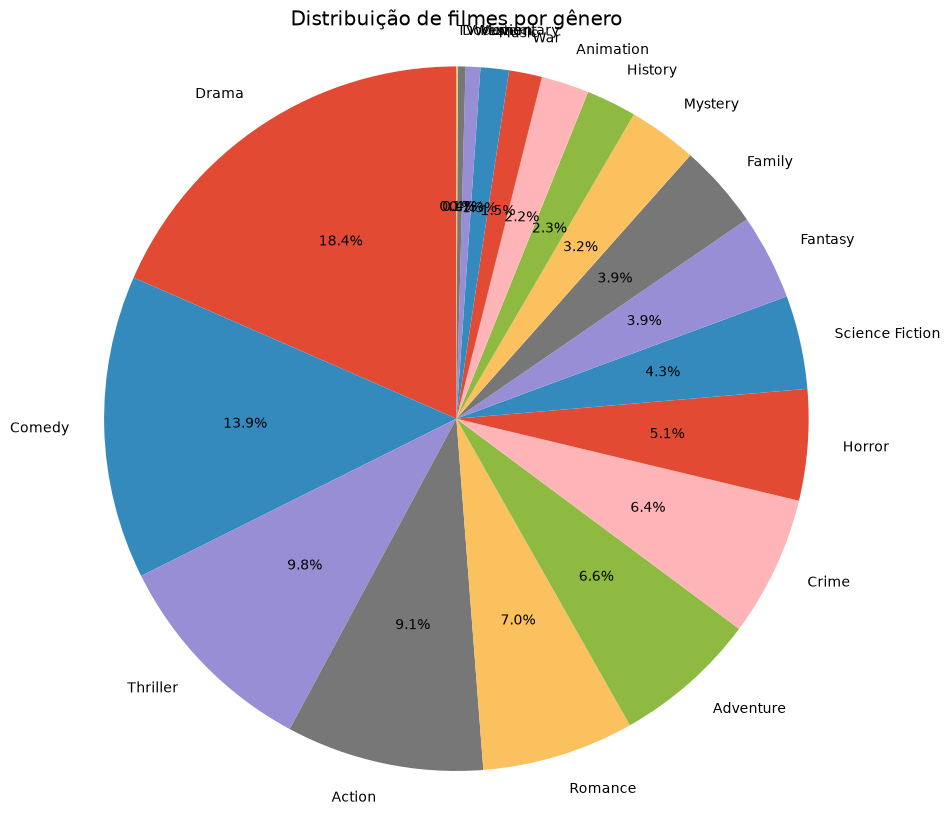

In [11]:
genre_counts = df_genres['genre'].dropna().value_counts()

plt.figure(figsize=(10, 10))
plt.pie(
    genre_counts,
    labels=genre_counts.index,
    autopct='%1.1f%%',
    startangle=90
)
plt.title('Distribuição de filmes por gênero')
plt.axis('equal')
plt.show()

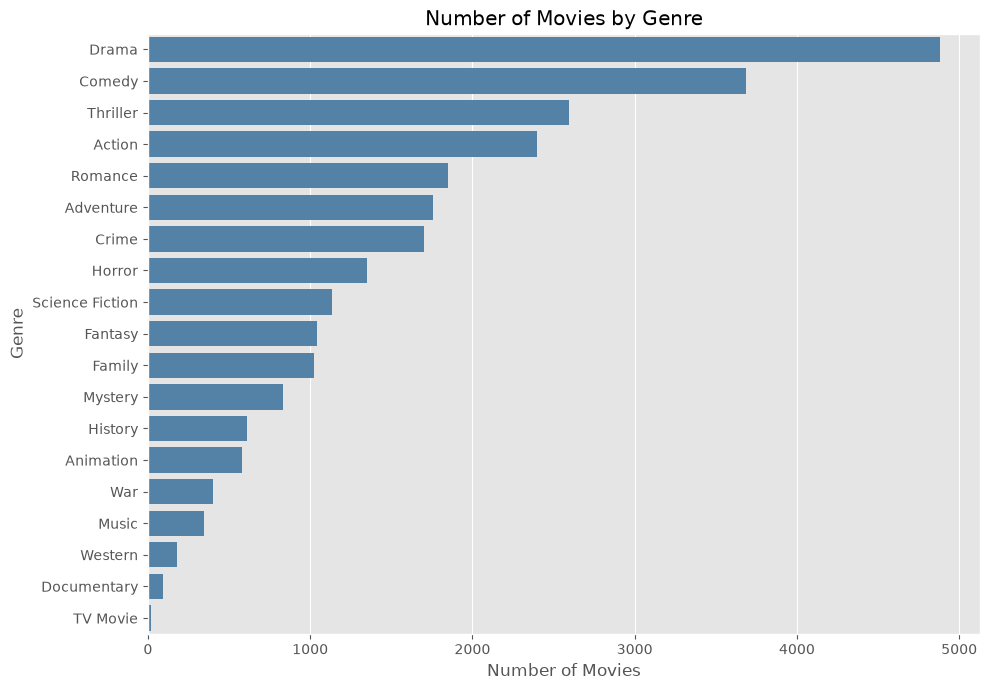

In [12]:
plt.figure(figsize=(10, 7))

ax = sns.barplot(
    x=genre_counts.values,
    y=genre_counts.index,
    color='steelblue'
)

ax.set_title('Number of Movies by Genre')
ax.set_xlabel('Number of Movies')
ax.set_ylabel('Genre')

plt.tight_layout()
plt.show()

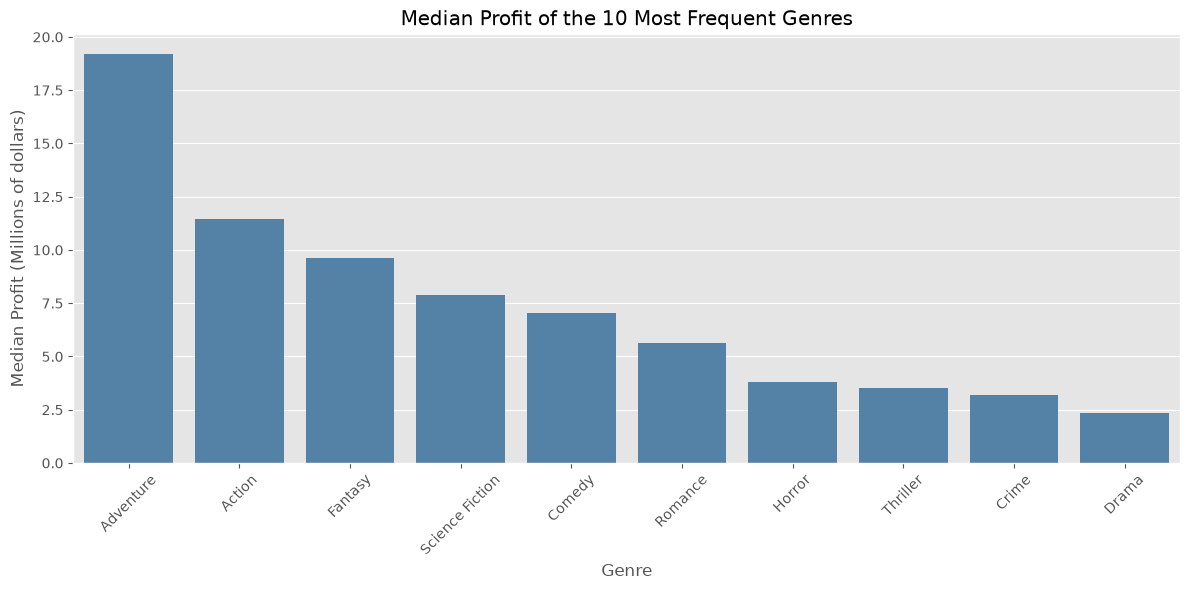

In [13]:
top_10_genres = genre_counts.head(10).index

median_profit_by_genre = (
    df_genres[df_genres['genre'].isin(top_10_genres)]
    .groupby('genre')['profit']
    .median()
    .sort_values(ascending=False)
    / 1_000_000
)

plt.figure(figsize=(12, 6))
ax = sns.barplot(
    x=median_profit_by_genre.index,
    y=median_profit_by_genre.values,
    color='steelblue'
)

ax.set_title('Median Profit of the 10 Most Frequent Genres')
ax.set_xlabel('Genre')
ax.set_ylabel('Median Profit (Millions of dollars)')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


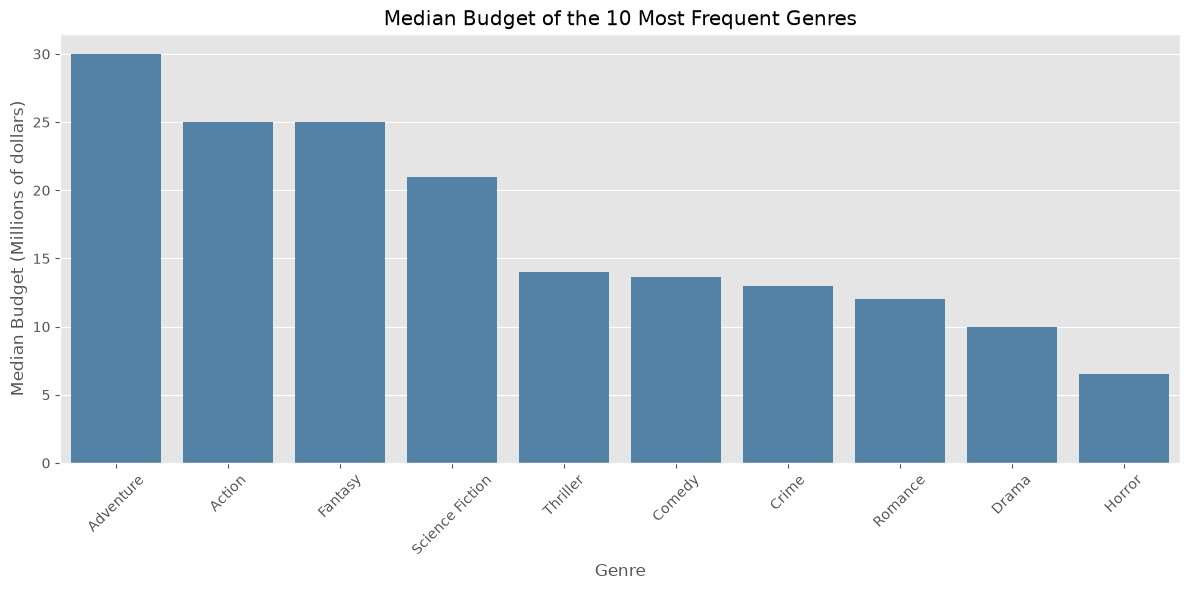

In [14]:
median_budget_by_genre = (
    df_genres[df_genres['genre'].isin(top_10_genres)]
    .groupby('genre')['budget']
    .median()
    .sort_values(ascending=False)
    / 1_000_000
)

plt.figure(figsize=(12, 6))
ax = sns.barplot(
    x=median_budget_by_genre.index,
    y=median_budget_by_genre.values,
    color='steelblue'
)

ax.set_title('Median Budget of the 10 Most Frequent Genres')
ax.set_xlabel('Genre')
ax.set_ylabel('Median Budget (Millions of dollars)')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

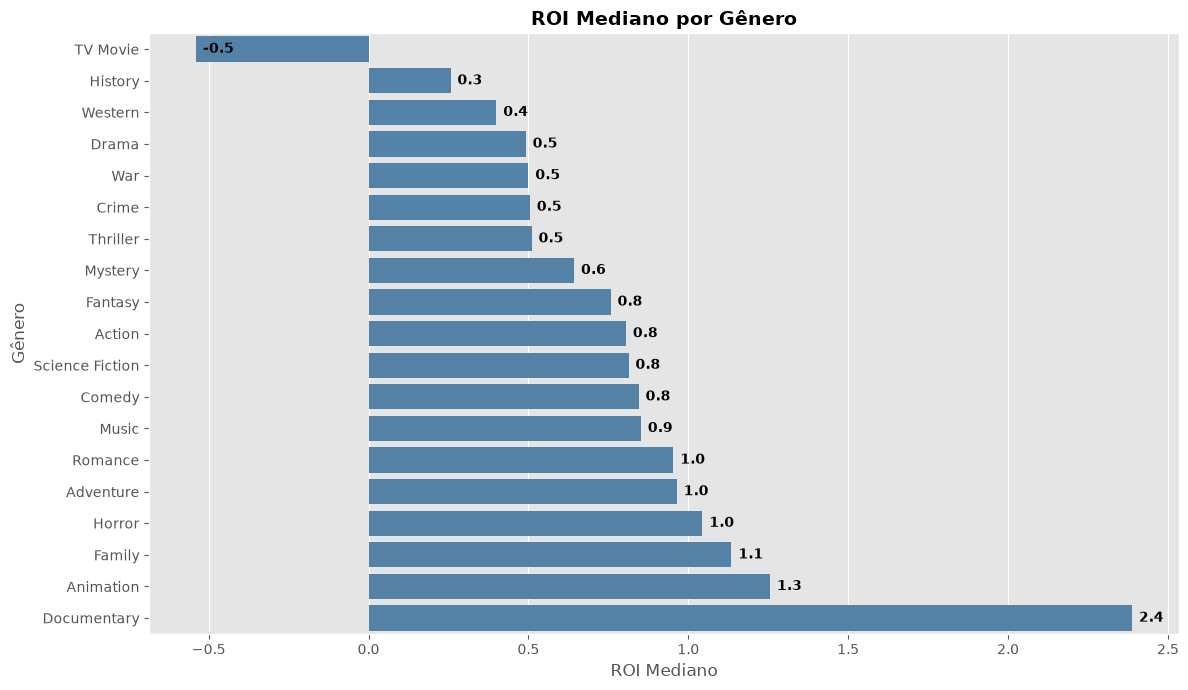

In [15]:
roi_by_genre = (
    df_genres.dropna(subset=['genre', 'roi'])
    .groupby('genre')['roi']
    .median()
    .sort_values()
)

plt.figure(figsize=(12, 7))

ax = sns.barplot(
    x=roi_by_genre.values,
    y=roi_by_genre.index,
    color='steelblue'
)

ax.set_title('ROI Mediano por Gênero', fontsize=14, fontweight='bold')
ax.set_xlabel('ROI Mediano', fontsize=12)
ax.set_ylabel('Gênero', fontsize=12)

for p in ax.patches:
    width = p.get_width()
    ax.annotate(
        f'{width:.1f}',
        xy=(width, p.get_y() + p.get_height() / 2),
        xytext=(5, 0),
        textcoords='offset points',
        ha='left',
        va='center',
        fontsize=10,
        fontweight='bold'
    )

plt.tight_layout()
plt.show()

## Divisão Por Coleções

In [16]:
df['collection'] = df['belongs_to_collection'].apply(
    lambda collection: collection.get('name')
    if isinstance(collection, dict)
    else np.nan
)

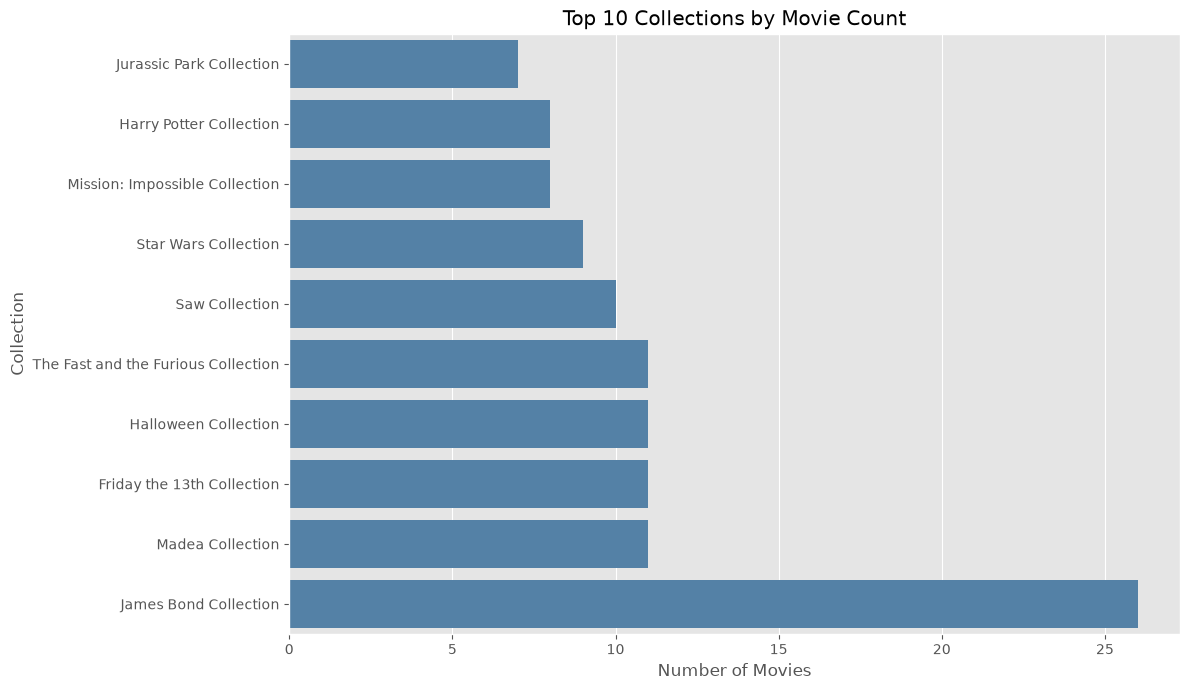

In [17]:
top_collections = (
    df['collection']
    .dropna()
    .value_counts()
    .head(10)
    .sort_values()
)

plt.figure(figsize=(12, 7))
ax = sns.barplot(
    x=top_collections.values,
    y=top_collections.index,
    color='steelblue'
)

ax.set_title('Top 10 Collections by Movie Count')
ax.set_xlabel('Number of Movies')
ax.set_ylabel('Collection')

plt.tight_layout()
plt.show()

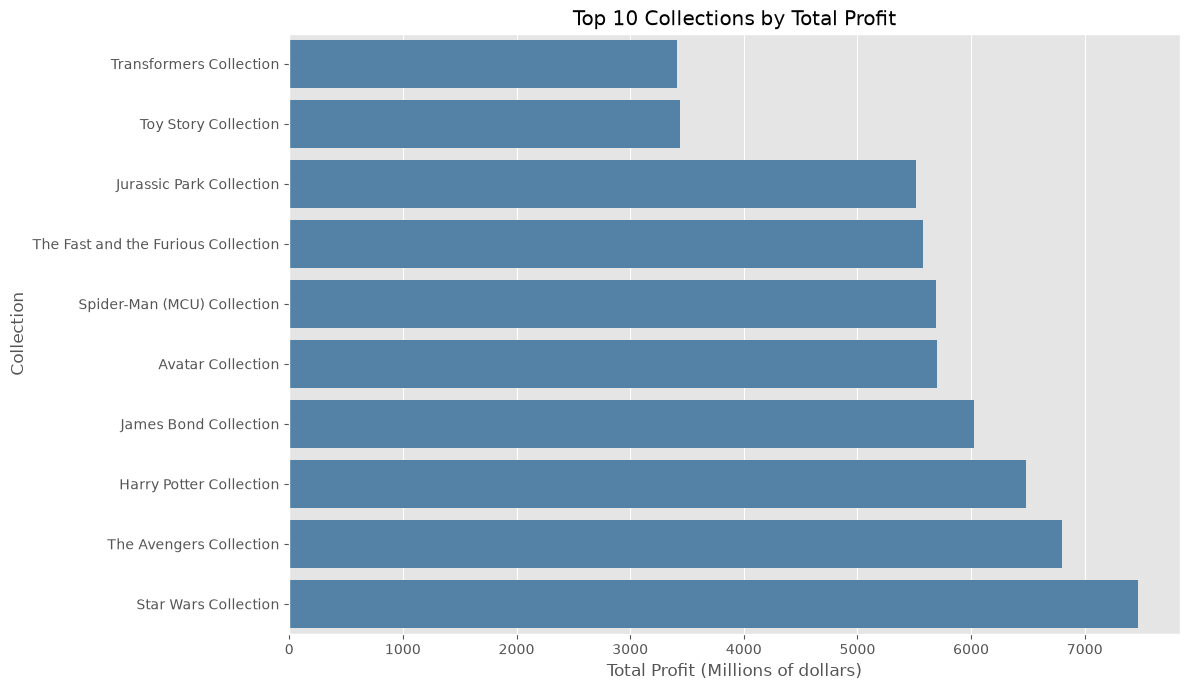

In [18]:
top_collections_by_profit = (
    df.dropna(subset=['collection'])
      .groupby('collection')['profit']
      .sum()
      .nlargest(10)
      .sort_values()
)

plt.figure(figsize=(12, 7))

ax = sns.barplot(
    x=top_collections_by_profit.values / 1_000_000,
    y=top_collections_by_profit.index,
    color='steelblue'
)

ax.set_title('Top 10 Collections by Total Profit')
ax.set_xlabel('Total Profit (Millions of dollars)')
ax.set_ylabel('Collection')

plt.tight_layout()
plt.show()

## Analise de ROI

In [19]:
top_roi_movies = (
    df
    .nlargest(10, 'roi')
    .sort_values('roi')
)

top_roi_movies[['title', 'roi', 'budget', 'revenue', 'vote_count']]


,title,roi,budget,revenue,vote_count
7644,Pink Flamingos,499.0000,12000,6000000,592
4380,One Cut of the Dead,525.4699,52406,27590180,1056
1417,Mr. Six,555.7654,250000,139191345,182
2539,Animal World,558.0856,125000,69885700,273
261,Obsession,696.6736,750000,523255189,6298
5143,The Brothers McMullen,772.0602,25000,19326506,107
1932,The Birth of a Nation,999.0000,100000,100000000,623
1933,Fist of Fury,999.0000,100000,100000000,1126
746,The Blair Witch Project,4142.9850,60000,248639099,5746
1002,Paranormal Activity,12889.3867,15000,193355800,5634


# Insights

## Companies

In [20]:
top_companies_millions = (
    company_median_revenue
    .nlargest(15)
    .div(1_000_000)
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 7))

ax = sns.barplot(
    x=top_companies_millions.values,
    y=top_companies_millions.index,
    color='steelblue'
)

ax.set_title('Top 15 Production Companies by Median Revenue')
ax.set_xlabel('Median Revenue (Millions of dollars)')
ax.set_ylabel('Production Company')

plt.tight_layout()
plt.show()


NameError: name 'company_median_revenue' is not defined

## Mês e dia da Semana

In [ ]:
# Conversão das datas e criação das variáveis de sazonalidade
df['release_date'] = pd.to_datetime(df['release_date'], errors='coerce')
df['release_month'] = df['release_date'].dt.month
df['release_day_name'] = df['release_date'].dt.day_name()

Novas Colunas: Release date, Release Month, Release day name

### Desempenho dos Filmes por Mês

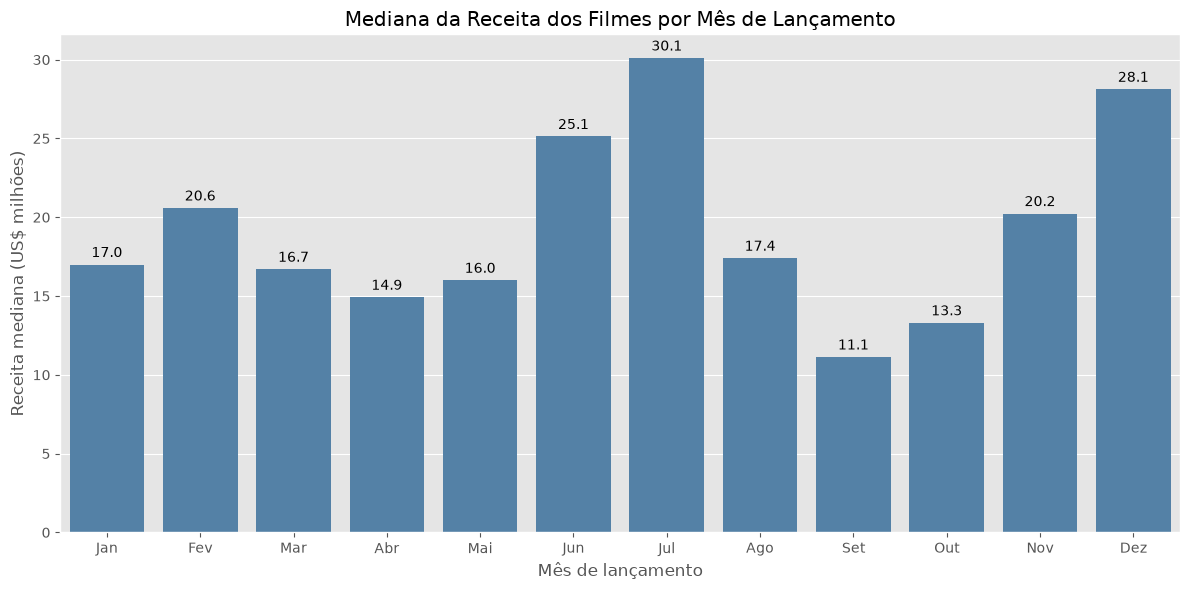

In [ ]:
receita_mediana_por_mes = (
    df.dropna(subset=['release_month', 'revenue'])
      .groupby('release_month')['revenue']
      .median()
      .reindex(range(1, 13))
      .div(1_000_000)
)

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    x=meses,
    y=receita_mediana_por_mes.values,
    color='steelblue'
)

ax.set_title('Mediana da Receita dos Filmes por Mês de Lançamento')
ax.set_xlabel('Mês de lançamento')
ax.set_ylabel('Receita mediana (US$ milhões)')

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f', padding=3)

plt.tight_layout()
plt.show()

A maioria dos Filmes Lançados no meio do ano e no final do ano tem desempenho melhor

### Receita por dia da semana

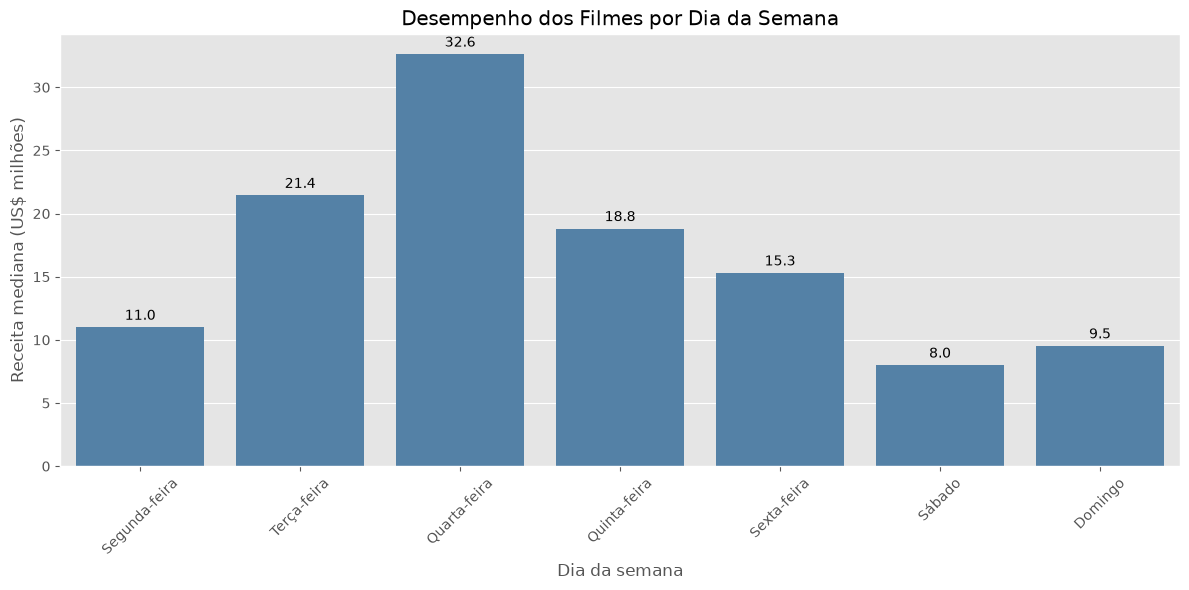

In [ ]:
# Tradução dos dias da semana
dias_pt = {
    'Monday': 'Segunda-feira',
    'Tuesday': 'Terça-feira',
    'Wednesday': 'Quarta-feira',
    'Thursday': 'Quinta-feira',
    'Friday': 'Sexta-feira',
    'Saturday': 'Sábado',
    'Sunday': 'Domingo'
}

day_performance['dia_semana'] = (
    day_performance['release_day_name'].map(dias_pt)
)

ordem_pt = [dias_pt[dia] for dia in day_order]

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=day_performance,
    x='dia_semana',
    y='receita_mediana_milhoes',
    order=ordem_pt,
    color='steelblue'
)

ax.set_title('Desempenho dos Filmes por Dia da Semana')
ax.set_xlabel('Dia da semana')
ax.set_ylabel('Receita mediana (US$ milhões)')
ax.tick_params(axis='x', rotation=45)

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f', padding=3)

plt.tight_layout()
plt.show()


Conclusão: A maioria dos Filmes Lançados na Quarta-Feira possuem maior Desempenho

### Filmes de Terror

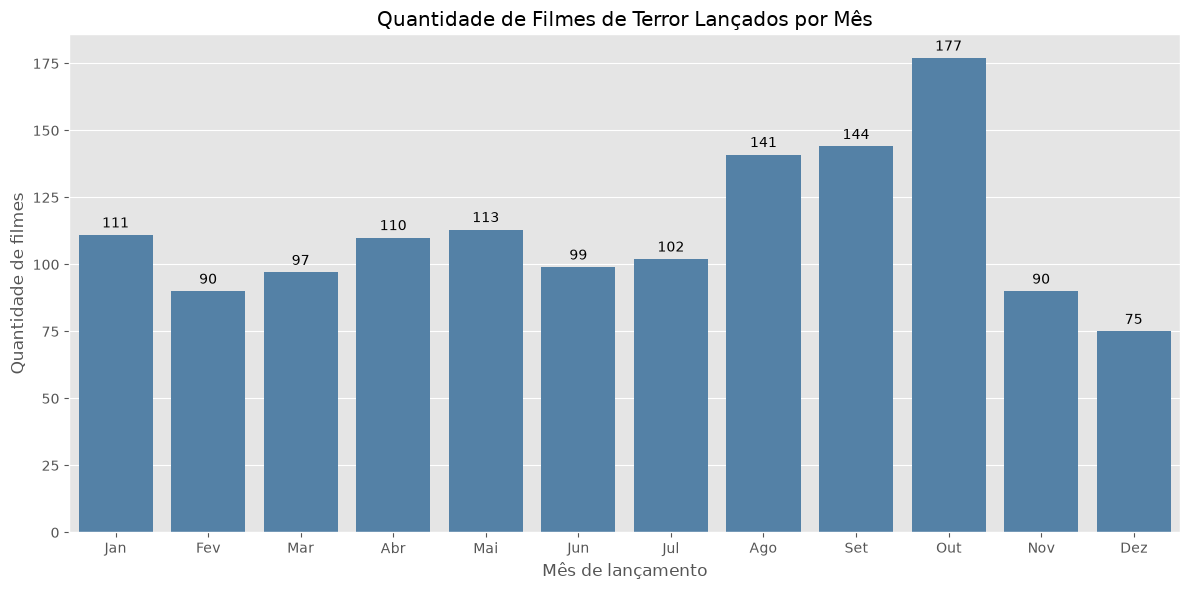

In [ ]:
terror_por_mes = (
    df_genres[df_genres['genre'] == 'Horror']
    .groupby('release_month')['id']
    .nunique()
    .reindex(range(1, 13), fill_value=0)
)

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    x=meses,
    y=terror_por_mes.values,
    color='steelblue'
)

ax.set_title('Quantidade de Filmes de Terror Lançados por Mês')
ax.set_xlabel('Mês de lançamento')
ax.set_ylabel('Quantidade de filmes')

for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3)

plt.tight_layout()
plt.show()

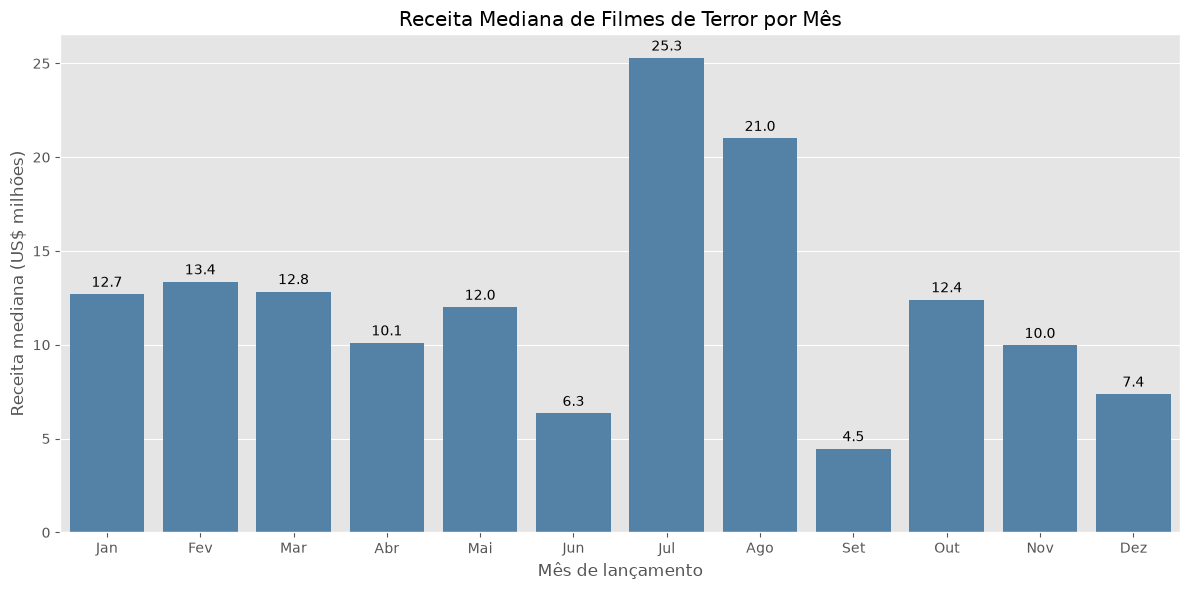

In [ ]:
receita_terror_por_mes = (
    df_genres[df_genres['genre'] == 'Horror']
    .groupby('release_month')['revenue']
    .median()
    .reindex(range(1, 13))
    .div(1_000_000)
)

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    x=meses,
    y=receita_terror_por_mes.values,
    color='steelblue'
)

ax.set_title('Receita Mediana de Filmes de Terror por Mês')
ax.set_xlabel('Mês de lançamento')
ax.set_ylabel('Receita mediana (US$ milhões)')

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f', padding=3)

plt.tight_layout()
plt.show()

Então apesar de muitos lançamentos em outubro, a maioria dos filmes tem maior receita em Julho em Agosto

## Ano e Décadas Popularidade

### Qtd de filmes por década

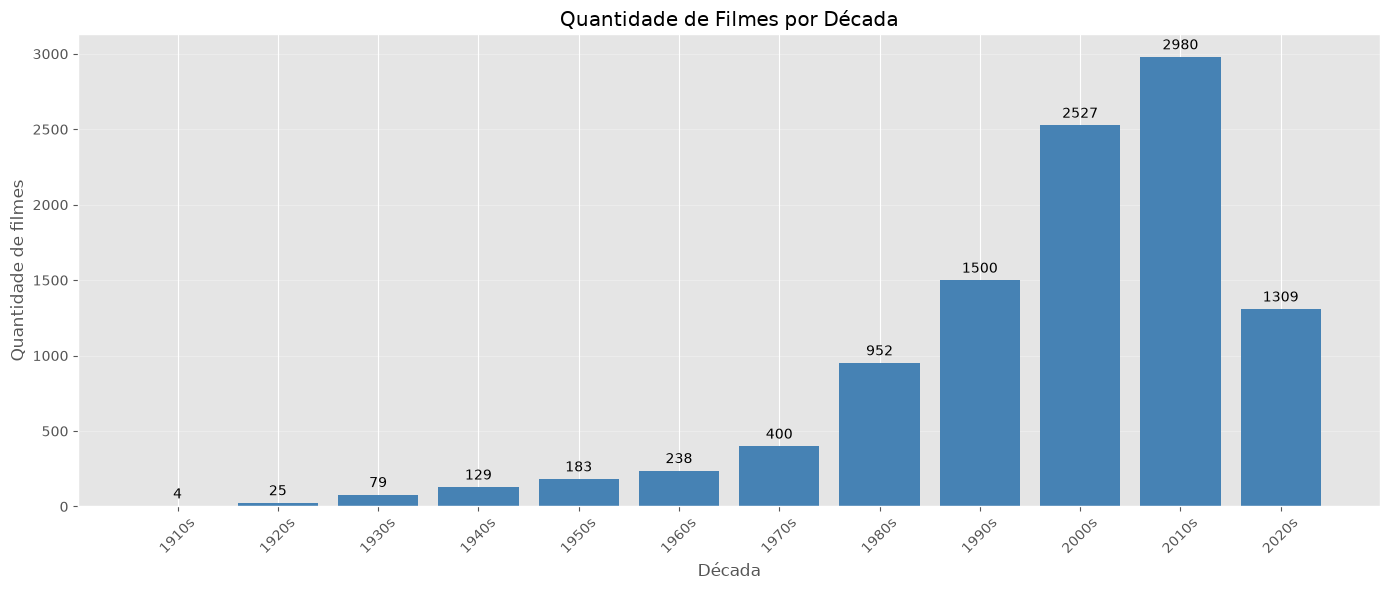

In [ ]:
plt.figure(figsize=(14, 6))

barras = plt.bar(
    filmes_por_decada.index.astype(str) + 's',
    filmes_por_decada.values,
    color='steelblue'
)

plt.bar_label(
    barras,
    labels=filmes_por_decada.values.astype(int),
    padding=3
)

plt.title('Quantidade de Filmes por Década')
plt.xlabel('Década')
plt.ylabel('Quantidade de filmes')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()


### Top Gêneros Por década

In [ ]:
top_5_generos_por_decada = (
    df_genres
    .dropna(subset=['release_date', 'genre', 'revenue'])
    .assign(
        decada=lambda x: (
            pd.to_datetime(x['release_date']).dt.year // 10
        ) * 10
    )
    .groupby(['decada', 'genre'], as_index=False)['revenue']
    .sum()
    .sort_values(['decada', 'revenue'], ascending=[True, False])
    .assign(posicao=lambda x: x.groupby('decada').cumcount() + 1)
    .query('posicao <= 5')
    .pivot(index='decada', columns='posicao', values='genre')
    .rename(columns={
        1: 'Top 1',
        2: 'Top 2',
        3: 'Top 3',
        4: 'Top 4',
        5: 'Top 5'
    })
    .reset_index()
)

top_5_generos_por_decada

posicao,decada,Top 1,Top 2,Top 3,Top 4,Top 5
0,1910,Drama,History,War,Action,Adventure
1,1920,Drama,Romance,War,Adventure,Comedy
2,1930,Drama,Romance,War,Fantasy,Family
3,1940,Drama,Family,Animation,Romance,Fantasy
4,1950,Drama,Romance,Fantasy,Family,Adventure
5,1960,Drama,Adventure,Comedy,Romance,Family
6,1970,Drama,Action,Comedy,Thriller,Adventure
7,1980,Comedy,Drama,Action,Adventure,Thriller
8,1990,Drama,Comedy,Action,Thriller,Adventure
9,2000,Comedy,Adventure,Action,Drama,Thriller


In [ ]:
top_5_generos_por_decada = (
    df_genres
    .dropna(subset=['release_date', 'genre', 'profit'])
    .assign(
        decada=lambda x: (
            pd.to_datetime(x['release_date']).dt.year // 10
        ) * 10
    )
    .groupby(['decada', 'genre'], as_index=False)['profit']
    .sum()
    .sort_values(['decada', 'profit'], ascending=[True, False])
    .assign(posicao=lambda x: x.groupby('decada').cumcount() + 1)
    .query('posicao <= 5')
    .pivot(index='decada', columns='posicao', values='genre')
    .rename(columns={
        1: 'Top 1',
        2: 'Top 2',
        3: 'Top 3',
        4: 'Top 4',
        5: 'Top 5'
    })
    .reset_index()
)

top_5_generos_por_decada

posicao,decada,Top 1,Top 2,Top 3,Top 4,Top 5
0,1910,Drama,History,War,Action,Adventure
1,1920,Drama,Romance,War,Comedy,Adventure
2,1930,Drama,Romance,War,Fantasy,Family
3,1940,Family,Animation,Drama,Fantasy,Romance
4,1950,Drama,Romance,Family,Fantasy,Animation
5,1960,Adventure,Drama,Family,Comedy,Thriller
6,1970,Drama,Action,Comedy,Thriller,Adventure
7,1980,Comedy,Action,Drama,Adventure,Romance
8,1990,Drama,Comedy,Action,Adventure,Thriller
9,2000,Adventure,Comedy,Action,Drama,Fantasy


In [ ]:
top_5_generos_lancados_por_decada = (
    df_genres
    .dropna(subset=['release_date', 'genre', 'id'])
    .assign(
        decada=lambda x: (
            pd.to_datetime(x['release_date']).dt.year // 10
        ) * 10
    )
    .groupby(['decada', 'genre'])['id']
    .nunique()
    .reset_index(name='quantidade')
    .sort_values(['decada', 'quantidade'], ascending=[True, False])
    .assign(
        posicao=lambda x: x.groupby('decada').cumcount() + 1
    )
    .query('posicao <= 5')
    .pivot(index='decada', columns='posicao', values='genre')
    .rename(columns={
        1: 'Top 1',
        2: 'Top 2',
        3: 'Top 3',
        4: 'Top 4',
        5: 'Top 5'
    })
    .reset_index()
)

top_5_generos_lancados_por_decada

posicao,decada,Top 1,Top 2,Top 3,Top 4,Top 5
0,1910,Drama,History,Action,Adventure,Science Fiction
1,1920,Drama,Romance,Thriller,Comedy,Adventure
2,1930,Drama,Romance,Comedy,Crime,Horror
3,1940,Drama,Romance,Comedy,Thriller,Mystery
4,1950,Drama,Romance,Comedy,Adventure,Science Fiction
5,1960,Drama,Comedy,Romance,Adventure,Thriller
6,1970,Drama,Thriller,Comedy,Action,Crime
7,1980,Comedy,Drama,Action,Thriller,Horror
8,1990,Drama,Comedy,Thriller,Action,Crime
9,2000,Drama,Comedy,Thriller,Action,Romance


### Análise de Gêneros por Década

#### Comédia

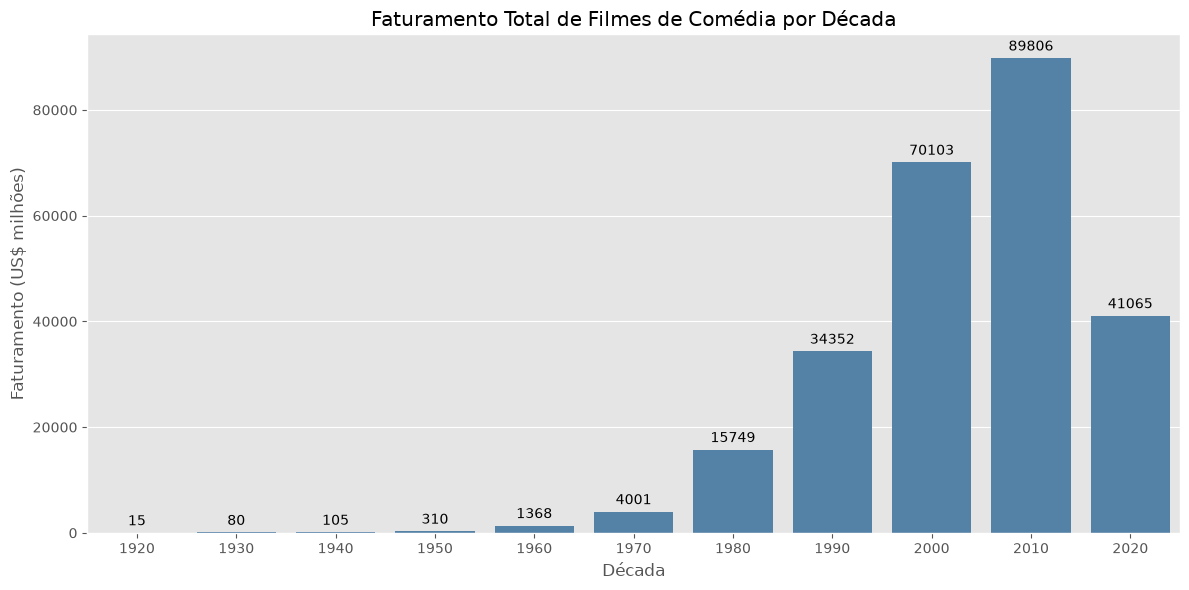

In [ ]:
plt.figure(figsize=(12, 6))

plt.plot(
    faturamento_comedia_por_decada.index,
    faturamento_comedia_por_decada.values,
    marker='o',
    color='steelblue',
    linewidth=2
)

plt.title('Faturamento Total de Filmes de Comédia por Década')
plt.xlabel('Década')
plt.ylabel('Faturamento (US$ milhões)')
plt.xticks(faturamento_comedia_por_decada.index)
plt.grid(True, alpha=0.3)

for decada, faturamento in faturamento_comedia_por_decada.items():
    plt.annotate(
        f'{faturamento:.0f}',
        (decada, faturamento),
        textcoords='offset points',
        xytext=(0, 8),
        ha='center'
    )

plt.tight_layout()
plt.show()


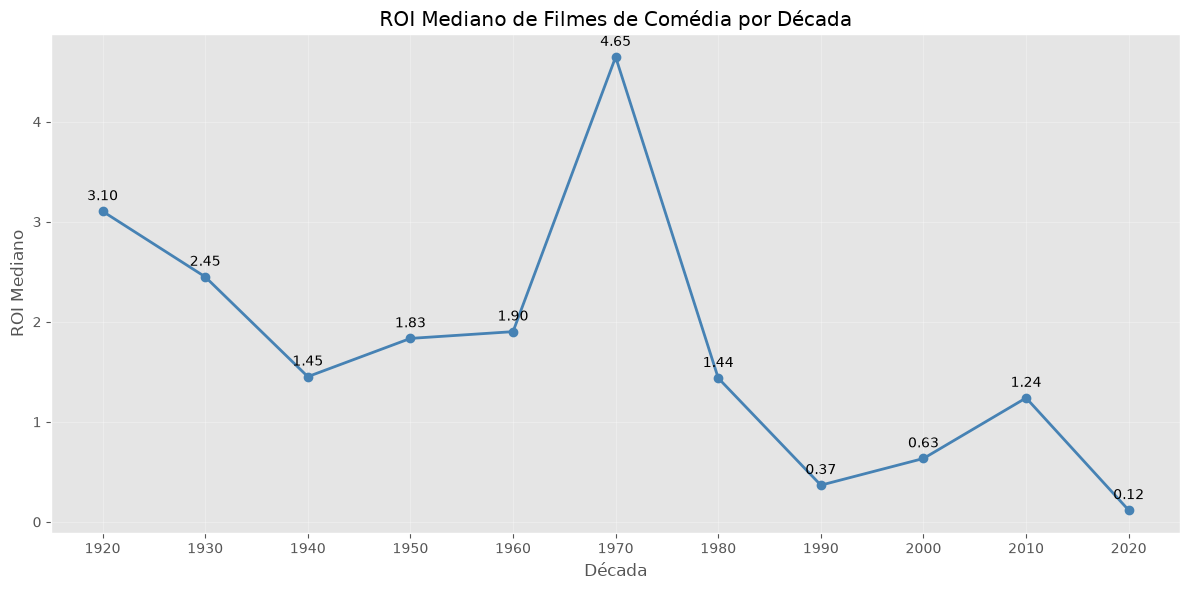

In [ ]:
roi_comedia_por_decada = (
    df_genres[df_genres['genre'] == 'Comedy']
    .dropna(subset=['release_date', 'roi'])
    .assign(
        decada=lambda x: (
            pd.to_datetime(x['release_date']).dt.year // 10
        ) * 10
    )
    .groupby('decada')['roi']
    .median()
    .sort_index()
)

plt.figure(figsize=(12, 6))

plt.plot(
    roi_comedia_por_decada.index,
    roi_comedia_por_decada.values,
    marker='o',
    color='steelblue',
    linewidth=2
)

plt.title('ROI Mediano de Filmes de Comédia por Década')
plt.xlabel('Década')
plt.ylabel('ROI Mediano')
plt.xticks(roi_comedia_por_decada.index)
plt.grid(True, alpha=0.3)

for decada, roi in roi_comedia_por_decada.items():
    plt.annotate(
        f'{roi:.2f}',
        (decada, roi),
        textcoords='offset points',
        xytext=(0, 8),
        ha='center'
    )

plt.tight_layout()
plt.show()

## Observações por Gênero

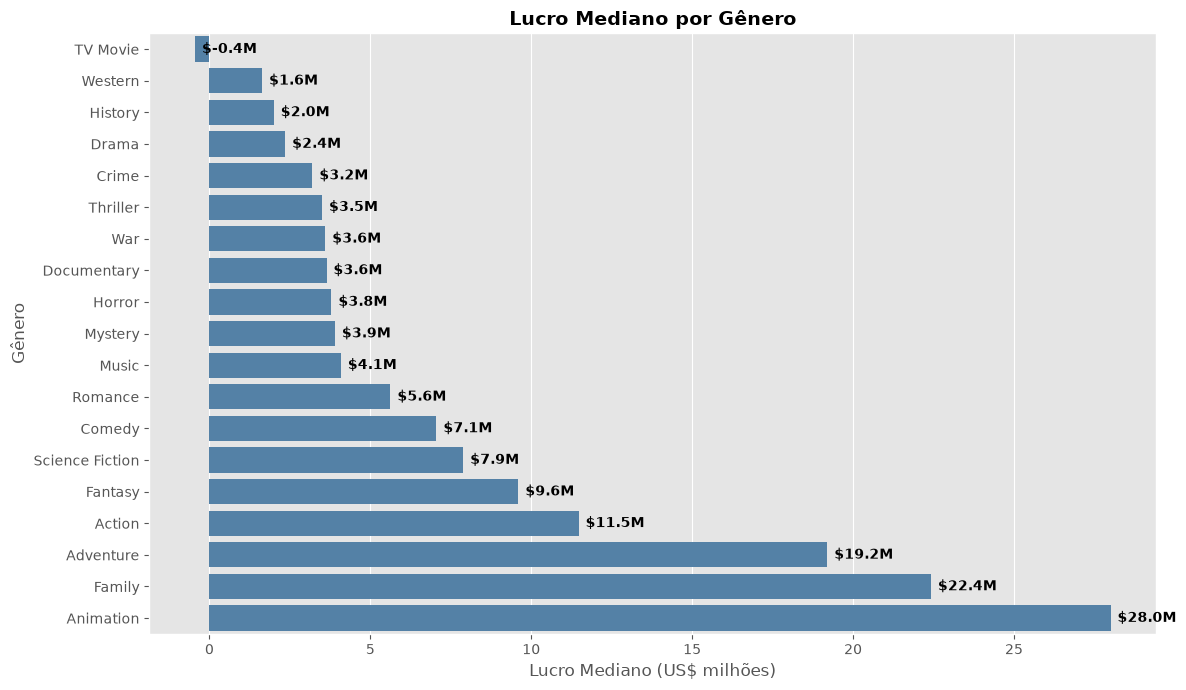

In [ ]:
lucro_mediano_por_genero = (
    df_genres.dropna(subset=['genre', 'profit'])
    .groupby('genre')['profit']
    .median()
    .div(1_000_000)
    .sort_values()
)

plt.figure(figsize=(12, 7))

ax = sns.barplot(
    x=lucro_mediano_por_genero.values,
    y=lucro_mediano_por_genero.index,
    color='steelblue'
)

ax.set_title('Lucro Mediano por Gênero', fontsize=14, fontweight='bold')
ax.set_xlabel('Lucro Mediano (US$ milhões)', fontsize=12)
ax.set_ylabel('Gênero', fontsize=12)

for p in ax.patches:
    width = p.get_width()
    ax.annotate(
        f'${width:.1f}M',
        xy=(width, p.get_y() + p.get_height() / 2),
        xytext=(5, 0),
        textcoords='offset points',
        ha='left',
        va='center',
        fontsize=10,
        fontweight='bold'
    )

plt.tight_layout()
plt.show()

Distribuição de Filmes por Gênero e Década:


decade,1910,1920,1930,1940,1950,1960,1970,1980,1990,2000,2010,2020,All
genre,,,,,,,,,,,,,
Action,1,3,6,4,8,21,90,230,343,567,773,354,2400
Adventure,1,5,10,16,28,45,65,164,224,410,530,257,1755
Animation,0,0,1,8,5,4,12,32,53,141,210,115,581
Comedy,0,6,30,27,35,67,105,376,641,1000,999,400,3686
Crime,0,4,11,18,26,29,80,162,316,461,433,163,1703
Documentary,0,0,0,1,0,0,3,6,4,33,35,11,93
Drama,4,18,45,71,105,121,203,363,737,1237,1445,535,4884
Family,0,0,6,14,8,15,16,73,171,278,294,149,1024
Fantasy,0,1,3,8,13,11,21,106,157,255,290,176,1041


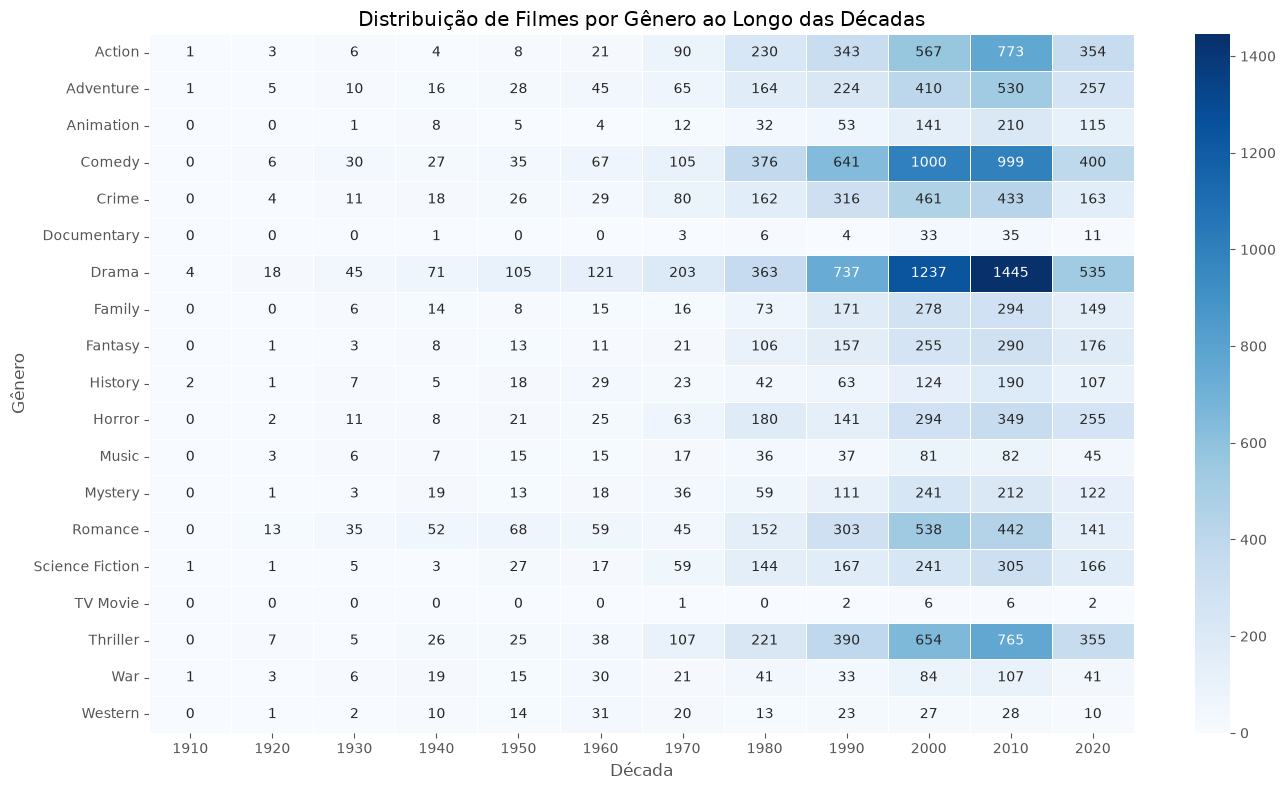

In [ ]:
# 4. Remover valores nulos e resetar o índice para evitar duplicidade de rótulos
df_genres_clean = df_genres.dropna(subset=['genre', 'decade']).reset_index(drop=True)

# 5. Cruzamento: Tabela cruzada (Crosstab) entre Gênero e Década (Contagem de filmes)
genre_decade_count = pd.crosstab(
    df_genres_clean['genre'], 
    df_genres_clean['decade'], 
    margins=True
)

print("Distribuição de Filmes por Gênero e Década:")
display(genre_decade_count)

# 6. Visualização: Gráfico de calor (Heatmap)
plt.figure(figsize=(14, 8))
genre_decade_heatmap = pd.crosstab(
    df_genres_clean['genre'], 
    df_genres_clean['decade']
)

sns.heatmap(
    genre_decade_heatmap, 
    cmap='Blues', 
    annot=True, 
    fmt='d', 
    linewidths=.5
)

plt.title('Distribuição de Filmes por Gênero ao Longo das Décadas')
plt.xlabel('Década')
plt.ylabel('Gênero')
plt.tight_layout()
plt.show()

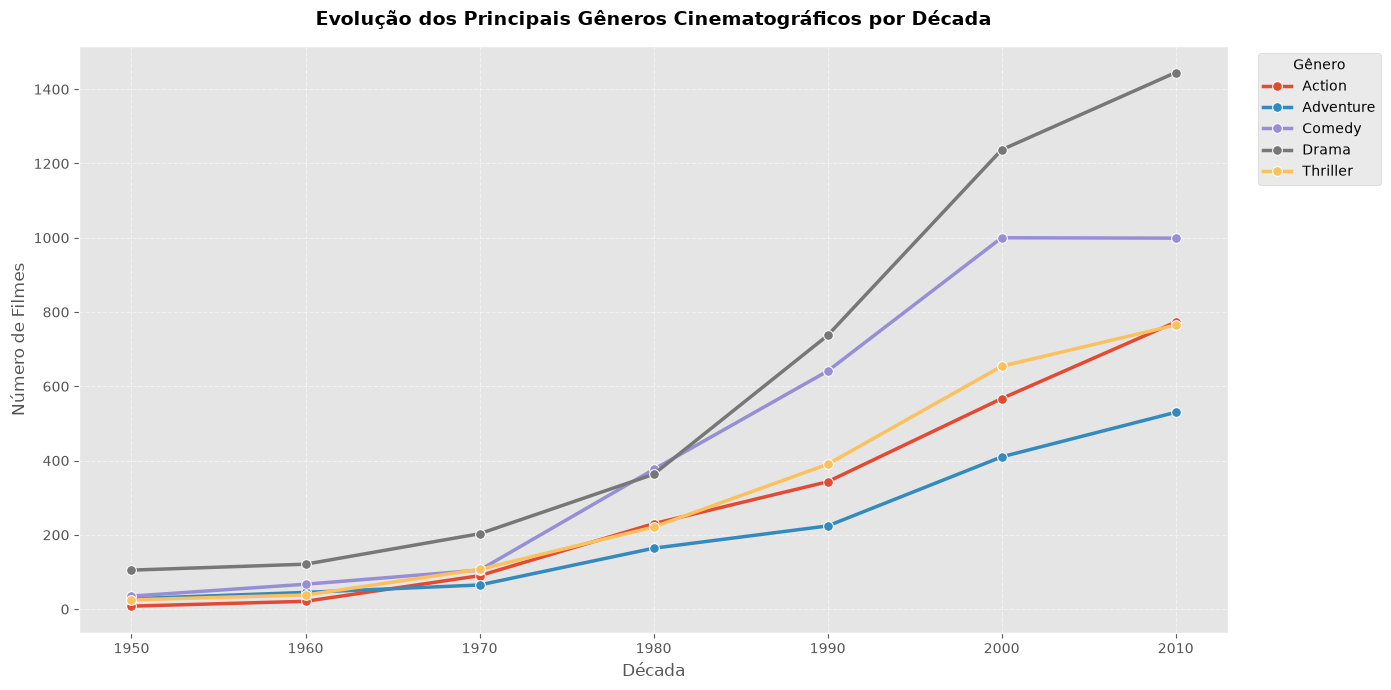

In [ ]:
# Importação das bibliotecas necessárias
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('ggplot')

# 1. Agrupar dados por década e gênero
genre_decade_counts = df_genres_clean.groupby(['decade', 'genre']).size().reset_index(name='count')

# 2. Filtrar apenas os gêneros principais para evitar poluição visual
principais_generos = ['Action', 'Adventure', 'Comedy', 'Drama', 'Thriller']
df_top = genre_decade_counts[
    genre_decade_counts['genre'].isin(principais_generos) & 
    (genre_decade_counts['decade'] >= 1950) & 
    (genre_decade_counts['decade'] < 2020)
]

# 3. Criar o gráfico limpo com linhas separadas para cada grande gênero
plt.figure(figsize=(14, 7))

sns.lineplot(
    data=df_top,
    x='decade',
    y='count',
    hue='genre',          
    marker='o',
    linewidth=2.5,
    markersize=7
)

plt.title('Evolução dos Principais Gêneros Cinematográficos por Década', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Década', fontsize=12)
plt.ylabel('Número de Filmes', fontsize=12)

# Ajustar legenda e grades para manter limpo
plt.legend(title='Gênero', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

=== DIAGNÓSTICO INICIAL (ANTES DO TRATAMENTO) ===
Total de registros brutos na base: 16541

=== RELATÓRIO DE REGISTRO: ANTES E DEPOIS DO TRATAMENTO POR DÉCADA ===
      Antes_Tratamento  Depois_Tratamento  Registros_Removidos  %_Perda_Filtro
1910                16                 15                    1            6.25
1920                62                 62                    0            0.00
1930               152                147                    5            3.29
1940               209                205                    4            1.91
1950               286                274                   12            4.20
1960               351                346                    5            1.42
1970               534                513                   21            3.93
1980              1216               1149                   67            5.51
1990              1811               1735                   76            4.20
2000              3258               3122      

<Figure size 1400x600 with 0 Axes>

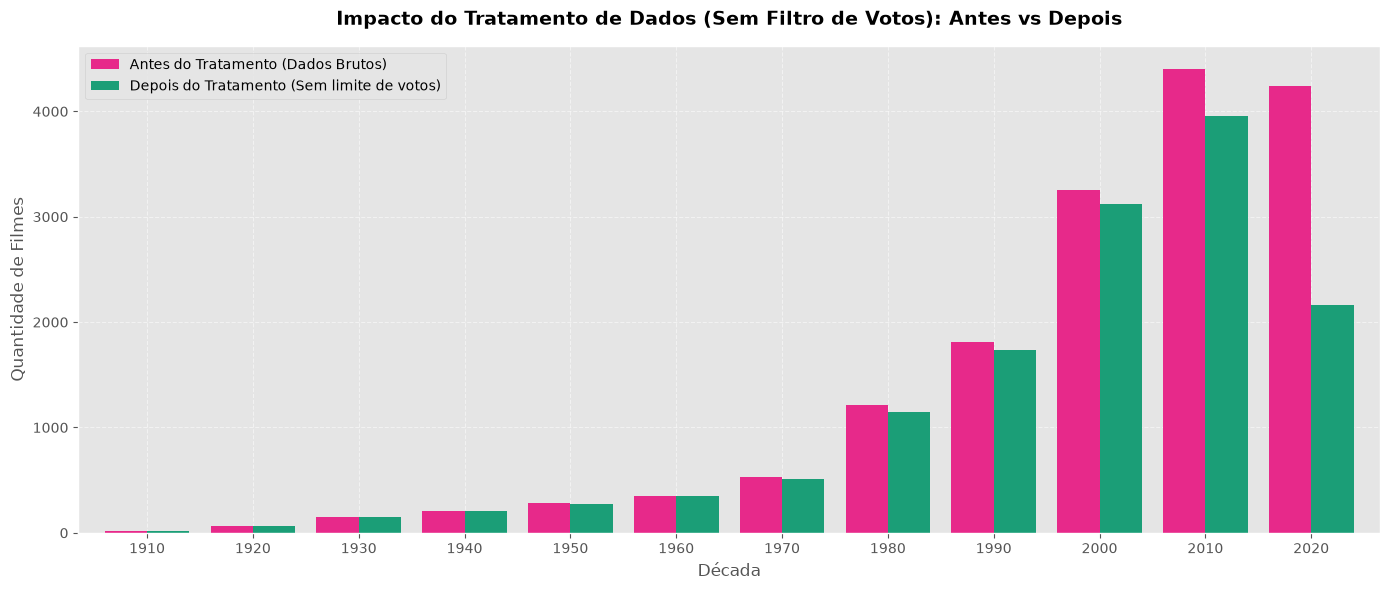

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Configuração visual
plt.style.use('ggplot')

# 1. CARREGAMENTO DOS DADOS BRUTOS
df_raw = pd.read_json('filmes.json', orient='records')

print("=== DIAGNÓSTICO INICIAL (ANTES DO TRATAMENTO) ===")
print(f"Total de registros brutos na base: {len(df_raw)}")

# Processamento temporal bruto para mapear falhas históricas
df_raw['release_date_dt'] = pd.to_datetime(df_raw['release_date'], errors='coerce')
df_raw['decade_raw'] = (df_raw['release_date_dt'].dt.year // 10) * 10

# Contagem antes de qualquer filtro
antes_contagem = df_raw['decade_raw'].value_counts().sort_index()


# 2. APLICAÇÃO DOS FILTROS E TRATAMENTO (SEM O FILTRO DE VOTOS)
# Mantemos apenas o controle de ROI e o orçamento mínimo (> 1000)
filtro_qualidade = (
    (df_raw['roi'] <= 50000) & 
    (df_raw['budget'] > 1000)
    # O filtro de vote_count > 50 foi removido daqui
)
df_filtered = df_raw[filtro_qualidade].copy()

# Tratamento dos gêneros (.explode)
df_genres = df_filtered.explode('genres').copy()
df_genres['genre'] = df_genres['genres'].apply(
    lambda x: x.get('name') if isinstance(x, dict) else np.nan
)

# Padronização de datas e cálculo da década até os dias atuais
df_genres['release_date'] = pd.to_datetime(df_genres['release_date'], errors='coerce')
df_genres['year'] = df_genres['release_date'].dt.year
df_genres['decade'] = (df_genres['year'] // 10) * 10

# Remoção de valores nulos cruciais
df_clean = df_genres.dropna(subset=['genre', 'decade']).reset_index(drop=True)


# 3. CONSOLIDAÇÃO DO ANTES E DEPOIS
depois_contagem = df_clean.groupby('decade')['title'].nunique()

# Criação da tabela de registro comparativo
tabela_comparativa = pd.DataFrame({
    'Antes_Tratamento': antes_contagem,
    'Depois_Tratamento': depois_contagem
}).fillna(0).sort_index()

# Cálculo de registros removidos e percentual de perda por falta de dados/erros
tabela_comparativa['Registros_Removidos'] = tabela_comparativa['Antes_Tratamento'] - tabela_comparativa['Depois_Tratamento']
tabela_comparativa['%_Perda_Filtro'] = (tabela_comparativa['Registros_Removidos'] / tabela_comparativa['Antes_Tratamento']) * 100

print("\n=== RELATÓRIO DE REGISTRO: ANTES E DEPOIS DO TRATAMENTO POR DÉCADA ===")
print(tabela_comparativa.round(2))


# 4. GERAÇÃO DO GRÁFICO COMPARATIVO
plt.figure(figsize=(14, 6))

tabela_comparativa[['Antes_Tratamento', 'Depois_Tratamento']].plot(
    kind='bar', 
    figsize=(14, 6), 
    color=['#e7298a', '#1b9e77'],
    width=0.8
)

plt.title('Impacto do Tratamento de Dados (Sem Filtro de Votos): Antes vs Depois', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Década', fontsize=12)
plt.ylabel('Quantidade de Filmes', fontsize=12)
plt.legend(['Antes do Tratamento (Dados Brutos)', 'Depois do Tratamento (Sem limite de votos)'], loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()